In [1]:
# ============================================================
# 01_exploration.ipynb — Data Exploration & Visualization
# Tasnim — Hotel Sentiment Project
# Label : basé sur la colonne source (Positive_Review / Negative_Review)
# Pas de Neutre — uniquement Positive et Negative
# ============================================================

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

In [3]:
# ── 1. LOAD DATA ────────────────────────────────────────────
df = pd.read_csv('../data/raw/Hotel_Reviews.csv')
print('Shape:', df.shape)
print(df.head(2))

Shape: (515738, 17)
                                       Hotel_Address  \
0   s Gravesandestraat 55 Oost 1092 AA Amsterdam ...   
1   s Gravesandestraat 55 Oost 1092 AA Amsterdam ...   

   Additional_Number_of_Scoring Review_Date  Average_Score   Hotel_Name  \
0                           194    8/3/2017            7.7  Hotel Arena   
1                           194    8/3/2017            7.7  Hotel Arena   

  Reviewer_Nationality                                    Negative_Review  \
0              Russia    I am so angry that i made this post available...   
1             Ireland                                         No Negative   

   Review_Total_Negative_Word_Counts  Total_Number_of_Reviews  \
0                                397                     1403   
1                                  0                     1403   

                                     Positive_Review  \
0   Only the park outside of the hotel was beauti...   
1   No real complaints the hotel was great gr

In [4]:
# ── 2. BASIC STATS ──────────────────────────────────────────
print('Colonnes:', df.columns.tolist())
print('\nTypes:')
print(df.dtypes)
print('\nValeurs manquantes:')
print(df.isnull().sum())
print('\nReviewer_Score stats:')
print(df['Reviewer_Score'].describe())

Colonnes: ['Hotel_Address', 'Additional_Number_of_Scoring', 'Review_Date', 'Average_Score', 'Hotel_Name', 'Reviewer_Nationality', 'Negative_Review', 'Review_Total_Negative_Word_Counts', 'Total_Number_of_Reviews', 'Positive_Review', 'Review_Total_Positive_Word_Counts', 'Total_Number_of_Reviews_Reviewer_Has_Given', 'Reviewer_Score', 'Tags', 'days_since_review', 'lat', 'lng']

Types:
Hotel_Address                                     str
Additional_Number_of_Scoring                    int64
Review_Date                                       str
Average_Score                                 float64
Hotel_Name                                        str
Reviewer_Nationality                              str
Negative_Review                                   str
Review_Total_Negative_Word_Counts               int64
Total_Number_of_Reviews                         int64
Positive_Review                                   str
Review_Total_Positive_Word_Counts               int64
Total_Number_of_Review

In [5]:
# ── 3. CREER LES DEUX GROUPES SELON LA COLONNE SOURCE ───────
# Label = Negative si le texte vient de Negative_Review
# Label = Positive si le texte vient de Positive_Review
# On supprime les valeurs 'No Negative' et 'No Positive'

neg = df[~df['Negative_Review'].str.strip().isin(['No Negative', ''])][['Negative_Review', 'Hotel_Name', 'Average_Score', 'Reviewer_Score']].copy()
neg.rename(columns={'Negative_Review': 'review_text'}, inplace=True)
neg['label'] = 'Negative'

pos = df[~df['Positive_Review'].str.strip().isin(['No Positive', ''])][['Positive_Review', 'Hotel_Name', 'Average_Score', 'Reviewer_Score']].copy()
pos.rename(columns={'Positive_Review': 'review_text'}, inplace=True)
pos['label'] = 'Positive'

# Combiner les deux en gardant l'ordre original (neg puis pos par ligne)
neg['_idx'] = neg.index
pos['_idx'] = pos.index
df_combined = pd.concat([neg, pos], ignore_index=True)
df_combined = df_combined.sort_values('_idx').drop(columns='_idx').reset_index(drop=True)

print('Shape apres separation:', df_combined.shape)
print('\nDistribution des labels:')
print(df_combined['label'].value_counts())
print('\nExemple:')
print(df_combined[['review_text', 'label']].head(4))

Shape apres separation: (866608, 5)

Distribution des labels:
label
Positive    479609
Negative    386999
Name: count, dtype: int64

Exemple:
                                         review_text     label
0   I am so angry that i made this post available...  Negative
1   Only the park outside of the hotel was beauti...  Positive
2   No real complaints the hotel was great great ...  Positive
3   Location was good and staff were ok It is cut...  Positive


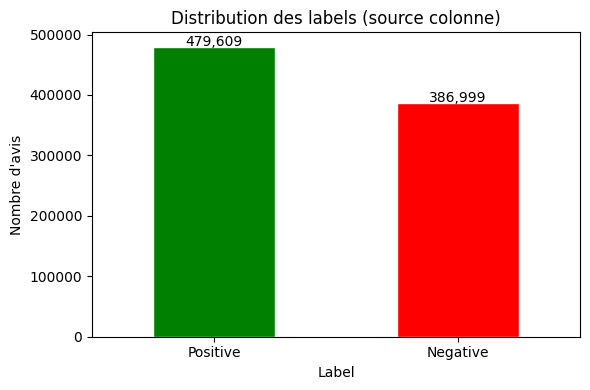

Positive: 479609
Negative: 386999


In [6]:
# ── 4. VISUALISATION — Distribution des labels ───────────────
plt.figure(figsize=(6, 4))
counts = df_combined['label'].value_counts()
colors = ['green', 'red']
counts.plot(kind='bar', color=colors, edgecolor='white')
plt.title('Distribution des labels (source colonne)')
plt.xlabel('Label')
plt.ylabel('Nombre d\'avis')
plt.xticks(rotation=0)
for i, v in enumerate(counts):
    plt.text(i, v + 2000, f'{v:,}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('../results/visualizations/sentiment_distribution.png')
plt.show()
print('Positive:', counts.get('Positive', 0))
print('Negative:', counts.get('Negative', 0))

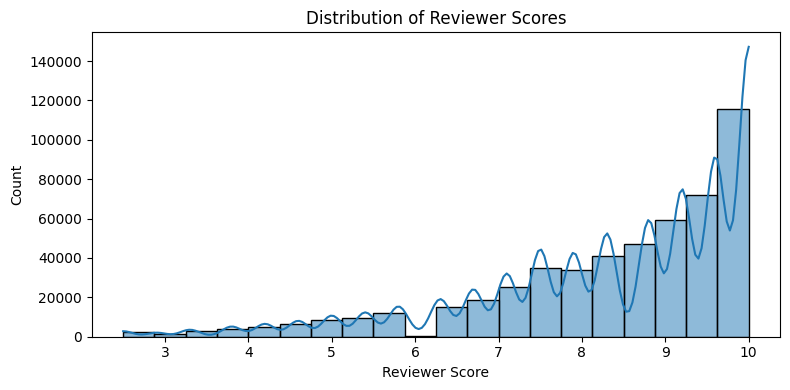

In [7]:
# ── 5. VISUALISATION — Distribution des Reviewer_Score ───────
plt.figure(figsize=(8, 4))
sns.histplot(df['Reviewer_Score'], bins=20, kde=True)
plt.title('Distribution of Reviewer Scores')
plt.xlabel('Reviewer Score')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../results/visualizations/rating_distribution.png')
plt.show()

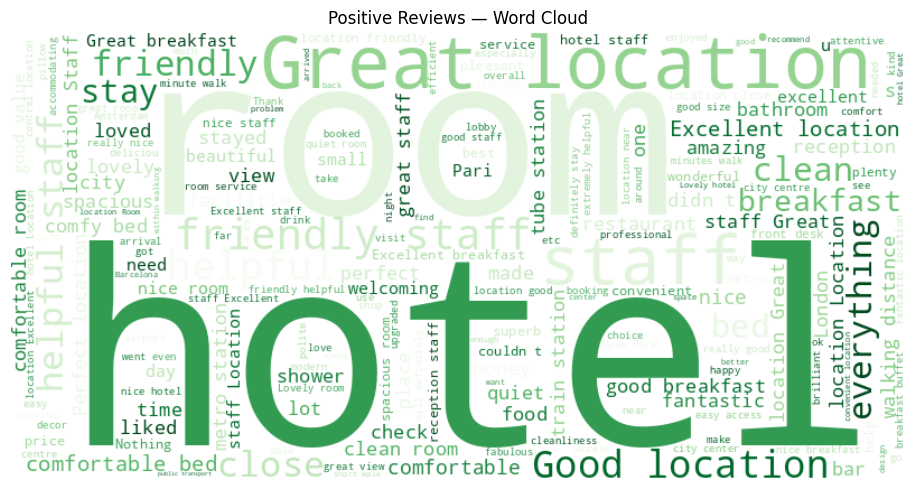

Word cloud Positive sauvegarde


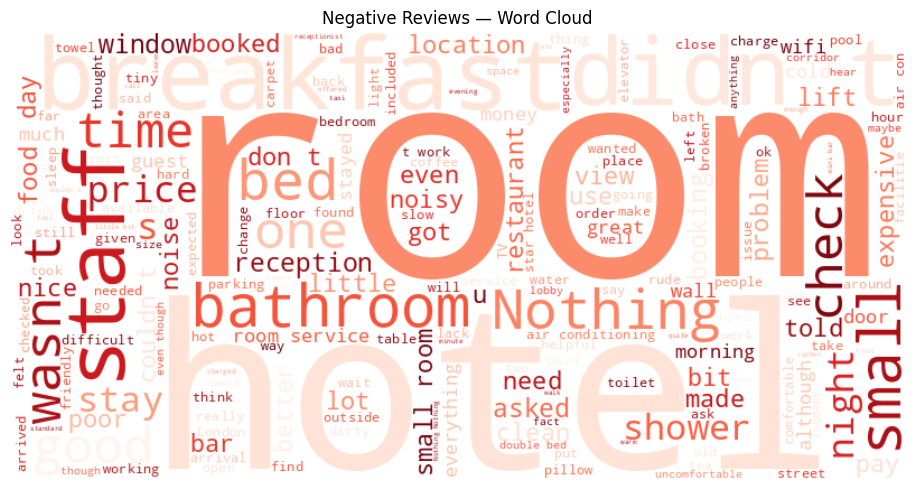

Word cloud Negative sauvegarde


In [8]:
# ── 6. WORD CLOUDS — Positive et Negative ────────────────────
for label, color in [('Positive', 'Greens'), ('Negative', 'Reds')]:
    text = ' '.join(
        df_combined[df_combined['label'] == label]['review_text'].dropna()
    )
    wc = WordCloud(
        width=800, height=400,
        background_color='white',
        colormap=color
    ).generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'{label} Reviews — Word Cloud')
    plt.tight_layout()
    plt.savefig(f'../results/visualizations/wordcloud_{label.lower()}.png')
    plt.show()
    print(f'Word cloud {label} sauvegarde')

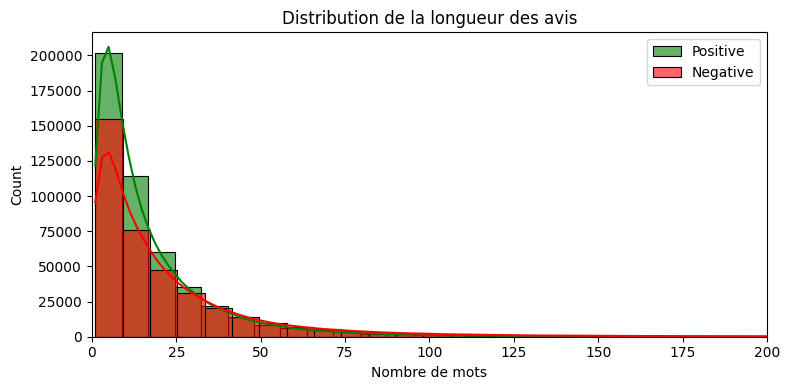

Longueur moyenne Positive: 17.6
Longueur moyenne Negative: 23.1


: 

In [ ]:
# ── 7. LONGUEUR DES AVIS ────────────────────────────────────
df_combined['review_length'] = df_combined['review_text'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(8, 4))
for label, color in [('Positive', 'green'), ('Negative', 'red')]:
    subset = df_combined[df_combined['label'] == label]['review_length']
    sns.histplot(subset, bins=50, color=color, label=label, alpha=0.6, kde=True)
plt.title('Distribution de la longueur des avis')
plt.xlabel('Nombre de mots')
plt.ylabel('Count')
plt.xlim(0, 200)
plt.legend()
plt.tight_layout()
plt.savefig('../results/visualizations/review_length_distribution.png')
plt.show()

print('Longueur moyenne Positive:', df_combined[df_combined['label']=='Positive']['review_length'].mean().round(1))
print('Longueur moyenne Negative:', df_combined[df_combined['label']=='Negative']['review_length'].mean().round(1))